# Baseline ALNS Solver — Validation Notebook

Validates the ALNS solver on Cordeau pr01 (3 vehicles, 24 requests).  
Checks: correctness, convergence, timing, bottlenecks.

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

import time
import numpy as np
import matplotlib.pyplot as plt

from src.parsers.cordeau import parse_cordeau
from src.solution import DARPSolution
from src.initial_solution import build_initial_solution
from src.solver import solve

DATA_DIR = PROJECT_ROOT / 'data' / 'cordeau'
KNOWN_BEST = 190.02

%matplotlib inline
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['figure.dpi'] = 100

## 1. Load Instance

In [2]:
inst = parse_cordeau(DATA_DIR / 'pr01.txt')

print(f'Instance: pr01')
print(f'  Requests:       {inst.num_requests}')
print(f'  Vehicles:       {inst.num_vehicles}')
print(f'  Capacity:       {inst.vehicle_capacity}')
print(f'  Max ride time:  {inst.max_ride_time}')
print(f'  Max route dur:  {inst.max_route_duration}')
print(f'  Total nodes:    {len(inst.nodes)}')

Instance: pr01
  Requests:       24
  Vehicles:       3
  Capacity:       6
  Max ride time:  90.0
  Max route dur:  480.0
  Total nodes:    50


## 2. Initial Solution (Greedy Construction)

In [4]:
t0 = time.perf_counter()
init_sol = build_initial_solution(inst)
construction_time = time.perf_counter() - t0

feasible, reason = init_sol.is_feasible()

print(f'Objective:        {init_sol.objective():.2f}')
print(f'Gap to known best: {(init_sol.objective() / KNOWN_BEST - 1) * 100:.1f}%')
print(f'Feasible:         {feasible}')
print(f'Unassigned:       {len(init_sol.unassigned)}')
print(f'Construction time: {construction_time:.3f}s')
print()
for k, route in enumerate(init_sol.routes):
    n_req = sum(1 for nid in route if 1 <= nid <= inst.num_requests)
    print(f'  Route {k}: {n_req} requests, {len(route)} nodes')

Objective:        256.68
Gap to known best: 35.1%
Feasible:         True
Unassigned:       0
Construction time: 0.156s

  Route 0: 11 requests, 24 nodes
  Route 1: 12 requests, 26 nodes
  Route 2: 1 requests, 4 nodes


## 3. Run ALNS

In [5]:
result = solve(inst, max_iterations=2000, seed=42)

best = result.best
feasible, reason = best.is_feasible()

print(f'\nInitial obj:      {result.initial.objective():.2f}')
print(f'Best obj:         {best.objective():.2f}')
print(f'Known best:       {KNOWN_BEST}')
print(f'Gap to known:     {(best.objective() / KNOWN_BEST - 1) * 100:.1f}%')
print(f'Feasible:         {feasible}')
print(f'Construction:     {result.construction_time:.3f}s')
print(f'ALNS solve:       {result.solve_time:.1f}s')
print(f'Time/iteration:   {result.solve_time / 2000 * 1000:.1f}ms')

Initial solution: obj=256.68, unassigned=0 (0.153s)
Best solution:    obj=192.64 (90.524s)

Initial obj:      256.68
Best obj:         192.64
Known best:       190.02
Gap to known:     1.4%
Feasible:         True
Construction:     0.153s
ALNS solve:       90.5s
Time/iteration:   45.3ms


## 4. Convergence

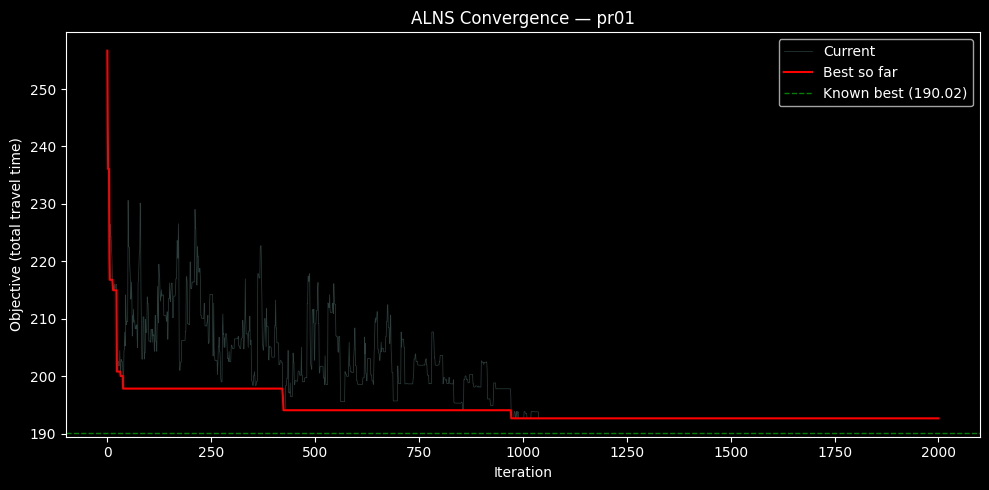

In [6]:
stats = result.alns_result.statistics
objectives = stats.objectives

# Track best-so-far
best_so_far = np.minimum.accumulate(objectives)

fig, ax = plt.subplots()
ax.plot(objectives, alpha=0.3, linewidth=0.5, label='Current')
ax.plot(best_so_far, color='red', linewidth=1.5, label='Best so far')
ax.axhline(y=KNOWN_BEST, color='green', linestyle='--', linewidth=1, label=f'Known best ({KNOWN_BEST})')
ax.set_xlabel('Iteration')
ax.set_ylabel('Objective (total travel time)')
ax.set_title('ALNS Convergence — pr01')
ax.legend()
plt.tight_layout()
plt.show()

## 5. Per-Iteration Timing

Total iterations: 2000
Mean:   45.3ms
Median: 42.5ms
P95:    89.4ms
Max:    198.2ms


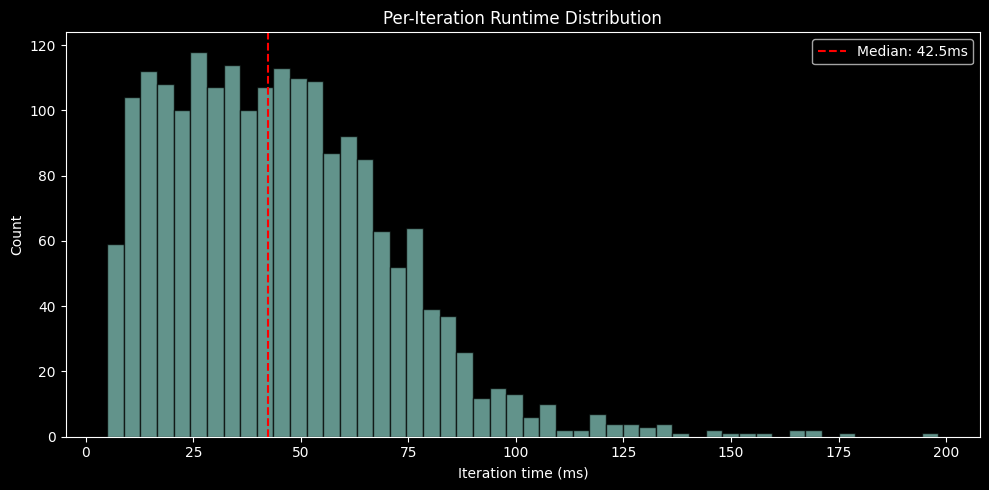

In [7]:
runtimes = stats.runtimes

print(f'Total iterations: {len(runtimes)}')
print(f'Mean:   {np.mean(runtimes)*1000:.1f}ms')
print(f'Median: {np.median(runtimes)*1000:.1f}ms')
print(f'P95:    {np.percentile(runtimes, 95)*1000:.1f}ms')
print(f'Max:    {np.max(runtimes)*1000:.1f}ms')

fig, ax = plt.subplots()
ax.hist(np.array(runtimes) * 1000, bins=50, edgecolor='black', alpha=0.7)
ax.axvline(np.median(runtimes) * 1000, color='red', linestyle='--', label=f'Median: {np.median(runtimes)*1000:.1f}ms')
ax.set_xlabel('Iteration time (ms)')
ax.set_ylabel('Count')
ax.set_title('Per-Iteration Runtime Distribution')
ax.legend()
plt.tight_layout()
plt.show()

## 6. Profile: Destroy vs Repair

In [8]:
from src.operators.destroy.random_removal import random_removal
from src.operators.repair.greedy_insertion import greedy_insertion

rng = np.random.default_rng(99)
test_sol = result.best.copy()

# Time destroy
destroy_times = []
repair_times = []
feasibility_times = []

for _ in range(50):
    t0 = time.perf_counter()
    destroyed = random_removal(test_sol, rng)
    destroy_times.append(time.perf_counter() - t0)

    t0 = time.perf_counter()
    repaired = greedy_insertion(destroyed, rng)
    repair_times.append(time.perf_counter() - t0)

    t0 = time.perf_counter()
    repaired.is_feasible()
    feasibility_times.append(time.perf_counter() - t0)

print(f'Destroy:     {np.mean(destroy_times)*1000:6.2f}ms')
print(f'Repair:      {np.mean(repair_times)*1000:6.2f}ms')
print(f'Feasibility: {np.mean(feasibility_times)*1000:6.2f}ms')
print(f'Total:       {(np.mean(destroy_times)+np.mean(repair_times)+np.mean(feasibility_times))*1000:6.2f}ms')
print()
pct_repair = np.mean(repair_times) / (np.mean(destroy_times) + np.mean(repair_times) + np.mean(feasibility_times)) * 100
print(f'Repair is {pct_repair:.0f}% of iteration time')

Destroy:       0.07ms
Repair:       40.01ms
Feasibility:   0.07ms
Total:        40.15ms

Repair is 100% of iteration time


## 7. Solution Comparison

In [9]:
print(f'{"":20s} {"Initial":>10s} {"ALNS Best":>10s} {"Known Best":>10s}')
print(f'{"Objective":20s} {result.initial.objective():10.2f} {best.objective():10.2f} {KNOWN_BEST:10.2f}')
print(f'{"Gap to known":20s} {(result.initial.objective()/KNOWN_BEST-1)*100:9.1f}% {(best.objective()/KNOWN_BEST-1)*100:9.1f}% {0:9.1f}%')
print()

# Per-route details for best solution
print('Best solution routes:')
n = inst.num_requests
for k, route in enumerate(best.routes):
    n_req = sum(1 for nid in route if 1 <= nid <= n)
    sched = best.compute_route_schedule(route)
    if sched.ride_time:
        max_rt = max(sched.ride_time.values())
        avg_rt = np.mean(list(sched.ride_time.values()))
    else:
        max_rt = avg_rt = 0
    duration = sched.begin_service[-1] - sched.departure_time[0]
    print(f'  Route {k}: {n_req:2d} requests, '
          f'duration={duration:.1f}/{inst.max_route_duration}, '
          f'max_ride={max_rt:.1f}/{inst.max_ride_time}, '
          f'avg_ride={avg_rt:.1f}')

                        Initial  ALNS Best Known Best
Objective                256.68     192.64     190.02
Gap to known              35.1%       1.4%       0.0%

Best solution routes:
  Route 0:  9 requests, duration=326.3/480.0, max_ride=89.5/90.0, avg_ride=46.6
  Route 1:  6 requests, duration=339.9/480.0, max_ride=90.0/90.0, avg_ride=44.6
  Route 2:  9 requests, duration=359.3/480.0, max_ride=90.0/90.0, avg_ride=65.8


## 8. Visualize Best Solution

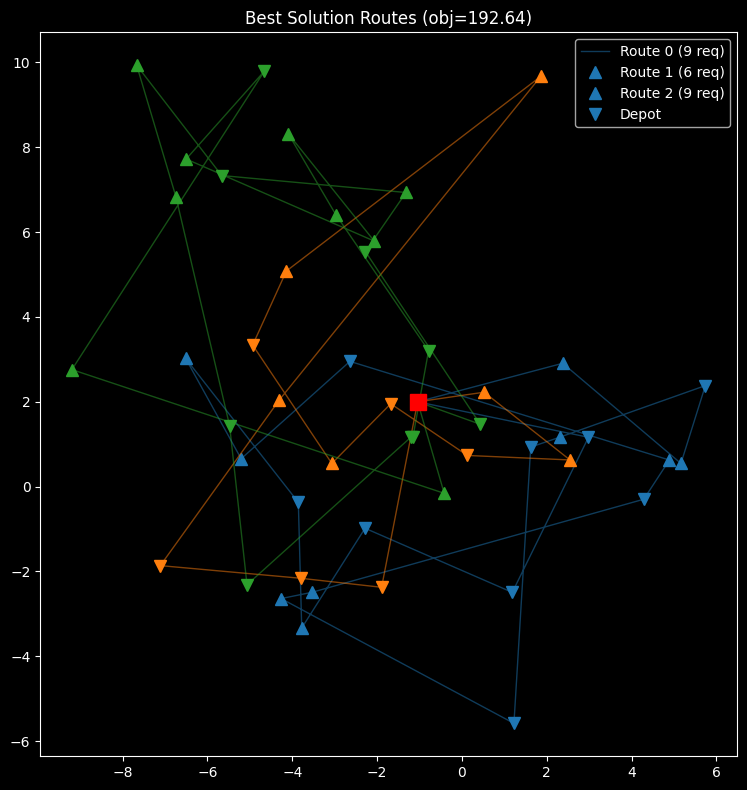

In [10]:
# Re-parse to get coordinates (parser stores them internally, re-extract)
from src.parsers.cordeau import parse_cordeau as _parse
import re

# Read coordinates directly from file
lines = (DATA_DIR / 'pr01.txt').read_text().strip().split('\n')
coords = {}
for line in lines[1:]:  # skip header
    parts = line.split()
    nid = int(parts[0])
    x, y = float(parts[1]), float(parts[2])
    coords[nid] = (x, y)
# Destination depot = same as origin
coords[2 * inst.num_requests + 1] = coords[0]

colors = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red', 'tab:purple']

fig, ax = plt.subplots(figsize=(10, 8))

# Plot routes
for k, route in enumerate(best.routes):
    xs = [coords[nid][0] for nid in route]
    ys = [coords[nid][1] for nid in route]
    c = colors[k % len(colors)]
    ax.plot(xs, ys, '-', color=c, alpha=0.5, linewidth=1)

    # Plot pickup/delivery nodes
    for nid in route:
        if nid == 0 or nid == 2 * inst.num_requests + 1:
            continue
        x, y = coords[nid]
        if 1 <= nid <= inst.num_requests:
            ax.plot(x, y, '^', color=c, markersize=8)  # pickup
        else:
            ax.plot(x, y, 'v', color=c, markersize=8)  # delivery

# Depot
ax.plot(coords[0][0], coords[0][1], 'rs', markersize=12, label='Depot')

ax.set_title(f'Best Solution Routes (obj={best.objective():.2f})')
ax.legend([f'Route {k} ({sum(1 for nid in r if 1<=nid<=inst.num_requests)} req)' for k, r in enumerate(best.routes)] + ['Depot'])
ax.set_aspect('equal')
plt.tight_layout()
plt.show()